In [12]:
# 打印数据类型
import os
from obspy import read

# 设置mseed文件目录路径
directory_path = 'C:\\Users\\22140\\OneDrive\\Desktop\\CUSUM\\DataAINOA'  # 替换为您的数据集路径

# 函数：读取并查看mseed文件的基本信息
def load_and_check_mseed_data(directory_path):
    for filename in os.listdir(directory_path):
        if filename.endswith(".mseed"):
            file_path = os.path.join(directory_path, filename)
            print(f"\nReading {filename}...\n")
            
            # 使用 obspy 读取 mseed 文件
            st = read(file_path)
            
            # 打印文件概况
            print("Stream Information:")
            print(st)
            
            # 打印每个 Trace（每个通道）的详细信息
            for tr in st:
                print("\nTrace Information:")
                print(tr)
                
                # 打印信号数据类型和长度
                print(f"Data type: {tr.data.dtype}")
                print(f"Data length: {len(tr.data)}")
                print(f"Start time: {tr.stats.starttime}")
                print(f"End time: {tr.stats.endtime}")
                print(f"Sampling rate: {tr.stats.sampling_rate}")
                print(f"Channel name: {tr.stats.channel}")
                print(f"Station name: {tr.stats.station}")

# 执行读取并查看数据
load_and_check_mseed_data(directory_path)


Reading st_anomaly_flow_final.mseed...

Stream Information:
9 Trace(s) in Stream:
AM.R016A.00.EHE | 2021-08-29T19:04:00.002999Z - 2021-08-29T20:10:00.002999Z | 100.0 Hz, 396001 samples
AM.R016A.00.EHN | 2021-08-29T19:04:00.002999Z - 2021-08-29T20:10:00.002999Z | 100.0 Hz, 396001 samples
AM.R016A.00.EHZ | 2021-08-29T19:04:00.002999Z - 2021-08-29T20:10:00.002999Z | 100.0 Hz, 396001 samples
AM.R7D9F.00.EHE | 2021-08-29T19:03:59.998000Z - 2021-08-29T20:09:59.998000Z | 100.0 Hz, 396001 samples
AM.R7D9F.00.EHN | 2021-08-29T19:03:59.998000Z - 2021-08-29T20:09:59.998000Z | 100.0 Hz, 396001 samples
AM.R7D9F.00.EHZ | 2021-08-29T19:03:59.998000Z - 2021-08-29T20:09:59.998000Z | 100.0 Hz, 396001 samples
AM.RFBA7.00.EHE | 2021-08-29T19:04:00.000000Z - 2021-08-29T20:10:00.000000Z | 100.0 Hz, 396001 samples
AM.RFBA7.00.EHN | 2021-08-29T19:04:00.000000Z - 2021-08-29T20:10:00.000000Z | 100.0 Hz, 396001 samples
AM.RFBA7.00.EHZ | 2021-08-29T19:04:00.000000Z - 2021-08-29T20:10:00.000000Z | 100.0 Hz, 39600

In [22]:
# cuda统一
import torch, os, random
import numpy as np

def setup_cuda(seed=0, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        device = torch.device("cuda")
        print("Using CUDA:", torch.cuda.get_device_name(0))
        torch.backends.cudnn.benchmark = not deterministic
        torch.backends.cudnn.deterministic = deterministic
    else:
        device = torch.device("cpu")
        print("CUDA not available, fallback to CPU")

    return device

device = setup_cuda(seed=0, deterministic=False)

def to_device(x, device=device):
    """把 tensor / numpy / list / tuple / dict 递归搬到 CUDA"""
    if torch.is_tensor(x):
        return x.to(device, non_blocking=True)
    if isinstance(x, np.ndarray):
        return torch.from_numpy(x).to(device, non_blocking=True)
    if isinstance(x, (list, tuple)):
        return type(x)(to_device(v, device) for v in x)
    if isinstance(x, dict):
        return {k: to_device(v, device) for k, v in x.items()}
    return x


Using CUDA: NVIDIA GeForce RTX 4060 Laptop GPU


In [77]:
# 读取mseed文件夹里的传感器数据
import os
import numpy as np
from obspy import read

def load_mseed_folder(folder_path, channel_whitelist=None, target_fs=100.0):
    """
    folder_path: 存放 mseed 文件的文件夹
    channel_whitelist: 只保留的通道名列表，比如 ["EHE","EHN","EHZ",...]
    target_fs: 目标采样率 100Hz
    """
    # 获取所有 mseed 文件
    files = [os.path.join(folder_path, f) for f in os.listdir(folder_path)
             if f.lower().endswith((".mseed", ".msd", ".miniseed"))]
    
    # 如果文件夹内没有找到 mseed 文件，抛出异常
    if len(files) == 0:
        raise FileNotFoundError(f"文件夹里没找到 mseed 文件 ({folder_path})")
    
    # 初始化流对象
    st = None
    for fp in files:
        try:
            s = read(fp)
            st = s if st is None else (st + s)
            print(f"加载文件: {fp}, 包含 {len(s)} traces")
        except Exception as e:
            print(f"读取文件 {fp} 时发生错误: {e}")
    
    # 如果没有加载任何数据，抛出异常
    if len(st) == 0:
        raise ValueError("加载的 mseed 数据为空，请检查文件")

    # 打印加载的通道名称
    print(f"Loaded {len(st)} traces from {len(files)} files.")
    available_channels = [tr.stats.channel for tr in st]
    print(f"Available channels: {available_channels}")  # 打印所有通道名称

    # 按需筛选通道（忽略大小写）
    if channel_whitelist is not None:
        available_channels_lower = [ch.lower() for ch in available_channels]
        channel_whitelist_lower = [ch.lower() for ch in channel_whitelist]
        matching_channels = [ch for ch in channel_whitelist_lower if ch in available_channels_lower]

        if not matching_channels:
            raise ValueError("没有找到匹配的通道，请检查 channel_list 是否正确")
        
        # 更新通道选择
        st = st.select(channel="|".join(matching_channels))

    # 合并同一通道的分段
    st.merge(method=1, fill_value="interpolate")

    # 重采样到目标采样率（100Hz）
    for tr in st:
        if abs(tr.stats.sampling_rate - target_fs) > 1e-6:
            tr.resample(target_fs)

    # 对齐所有数据到相同时间段
    if len(st) > 0:  # 确保 st 非空再进行处理
        t0 = max(tr.stats.starttime for tr in st)
        t1 = min(tr.stats.endtime for tr in st)
        st.trim(t0, t1)

    return st

# ======================
# 用法示例
folder_path = "C:\\Users\\22140\\OneDrive\\Desktop\\CUSUM\\DataAINOA"
channel_list = ["EHE", "EHN", "EHZ", "EH1", "EH2", "EH3", "EH4", "EH5"]
stream = load_mseed_folder(folder_path, channel_list, target_fs=100.0)

# 打印 stream 和通道信息
print("Stream loaded successfully.")
print([tr.stats.channel for tr in stream])  # 打印所有匹配的通道


加载文件: C:\Users\22140\OneDrive\Desktop\CUSUM\DataAINOA\st_anomaly_flow_final.mseed, 包含 9 traces
加载文件: C:\Users\22140\OneDrive\Desktop\CUSUM\DataAINOA\st_anomaly_no_flow_final.mseed, 包含 9 traces
加载文件: C:\Users\22140\OneDrive\Desktop\CUSUM\DataAINOA\st_no_anomaly_final.mseed, 包含 9 traces
Loaded 27 traces from 3 files.
Available channels: ['EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ', 'EHE', 'EHN', 'EHZ']
Stream loaded successfully.
[]


In [26]:
# 切成1s片段
def segment_stream_1s(stream, fs=100):
    stream_sorted = sorted(stream, key=lambda tr: tr.stats.channel)
    channel_names = [tr.stats.channel for tr in stream_sorted]

    min_len = min(len(tr.data) for tr in stream_sorted)
    min_len = (min_len // fs) * fs

    data = []
    for tr in stream_sorted:
        x = tr.data[:min_len].astype(np.float32)
        x = x.reshape(-1, fs)   # (N, fs)
        data.append(x)

    segments = np.stack(data, axis=0).transpose(1,0,2)  # (N, C, fs)
    return segments, channel_names

segments, ch_names = segment_stream_1s(stream, fs=100)
print("segments shape:", segments.shape)  # (N, 9, 100)


segments shape: (196440, 9, 100)


In [63]:
# 每秒每个传感器的Hjorth三参数
def hjorth_params_1segment(x, eps=1e-8):
    x = x.astype(np.float32)
    dx  = np.diff(x, prepend=x[0])
    ddx = np.diff(dx, prepend=dx[0])

    m0 = np.mean(x**2)
    m2 = np.mean(dx**2)
    m4 = np.mean(ddx**2)

    activity   = m0
    mobility   = np.sqrt((m2 + eps)/(m0 + eps))
    complexity = np.sqrt((m4 + eps)/(m2 + eps)) / (mobility + eps)
    return activity, mobility, complexity

def compute_hjorth_features(segments):
    N, C, fs = segments.shape
    hjorth = np.zeros((N, C, 3), dtype=np.float32)
    for i in range(N):
        for c in range(C):
            hjorth[i, c, :] = hjorth_params_1segment(segments[i, c, :])
    flat24 = hjorth.reshape(N, -1)
    return hjorth, flat24

hjorth, hjorth24 = compute_hjorth_features(segments)
print("hjorth:", hjorth.shape)     # (N,9,3)
print("hjorth24:", hjorth24.shape) # (N,27)


hjorth: (196440, 9, 3)
hjorth24: (196440, 27)


In [65]:
# 训练/测试划分（80/20）并标准化
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def split_and_scale_per_param(hjorth_normal, test_size=0.2, random_state=0):
    Xtr_list, Xte_list, scaler_list = [], [], []
    for p in range(3):
        Xp = hjorth_normal[:, :, p]  # (N, 9)
        Xtr, Xte = train_test_split(Xp, test_size=test_size, random_state=random_state, shuffle=True)

        scaler = StandardScaler().fit(Xtr)
        Xtr_s = scaler.transform(Xtr).astype(np.float32)
        Xte_s = scaler.transform(Xte).astype(np.float32)

        Xtr_list.append(Xtr_s)
        Xte_list.append(Xte_s)
        scaler_list.append(scaler)
    return Xtr_list, Xte_list, scaler_list


In [31]:
# PCA+凸包（逐一参数可视化）
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull

def plot_pca_with_hull(X8, labels=None, title="PCA"):
    pca = PCA(n_components=2)
    Z = pca.fit_transform(X8)

    plt.figure()
    if labels is None:
        plt.scatter(Z[:,0], Z[:,1], s=6)
    else:
        plt.scatter(Z[:,0], Z[:,1], c=labels, s=6, cmap="tab10")

    if len(Z) >= 3:
        hull = ConvexHull(Z)
        for simplex in hull.simplices:
            plt.plot(Z[simplex, 0], Z[simplex, 1], "k-", linewidth=1)

    plt.title(title); plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.show()


activity matrix: (196440, 9)
mobility matrix: (196440, 9)
complexity matrix: (196440, 9)


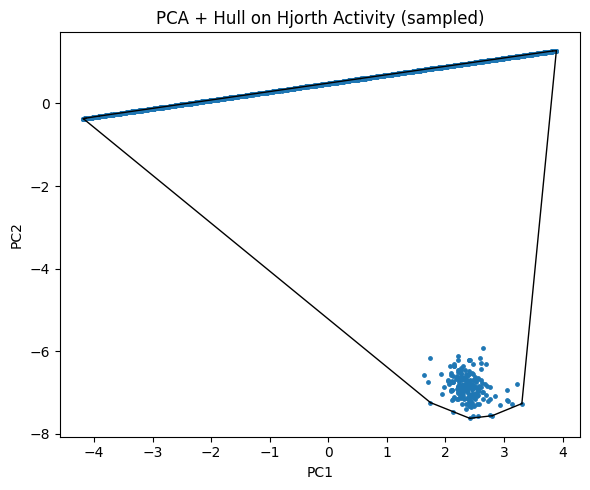

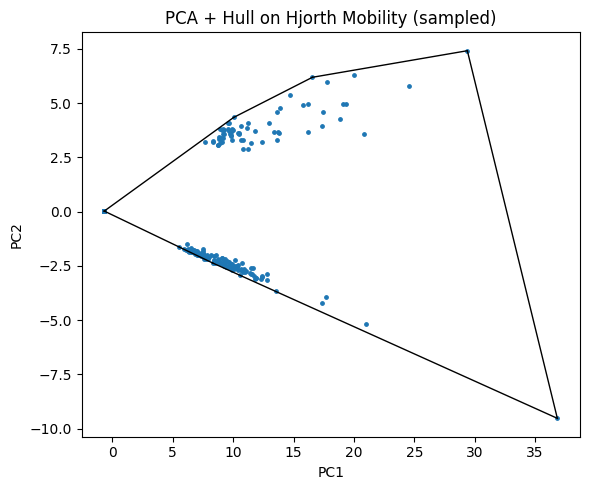

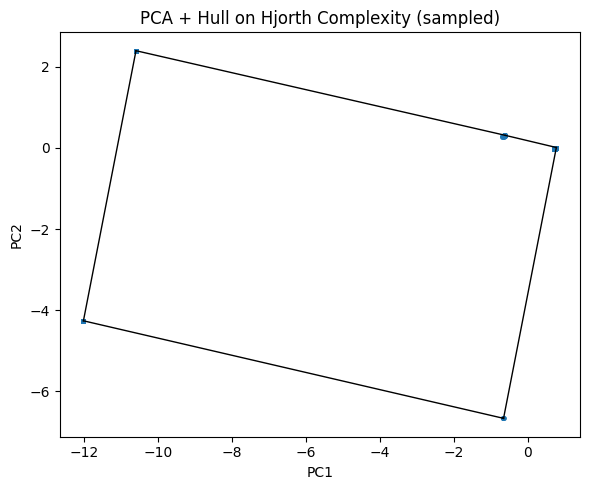

In [41]:
# Activity / Mobility / Complexity split PCA + Convex Hull
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull


def plot_pca_with_hull_sample(
    X,
    labels=None,
    label_names=None,          
    title="PCA + Convex Hull (sampled)",
    sample_size=3000,
    random_state=0,
    point_size=6,
    hull_linewidth=1.0,
    show=True,
):
    """
    X: (N, D) feature matrix
    labels: (N,) optional class labels for coloring
    label_names: optional legend names
        - dict: {0:"Normal",1:"Abnormal",...}
        - list/tuple: index by label value, e.g. ["Normal","Abnormal"]
    """
    X = np.asarray(X)
    if X.ndim != 2:
        raise ValueError(f"X must be 2D (N, D), got {X.shape}")

    N = X.shape[0]
    if N < 3:
        raise ValueError("Need at least 3 samples for PCA + hull")

    # remove NaN/Inf
    mask = np.isfinite(X).all(axis=1)
    if not mask.all():
        X = X[mask]
        if labels is not None:
            labels = np.asarray(labels)[mask]
        N = X.shape[0]
        print(f"[warn] removed {np.sum(~mask)} rows with NaN/Inf")

    if N < 3:
        raise ValueError("Too few samples after cleaning")

    # PCA -> 2D (fit on full data)
    pca = PCA(n_components=2)
    Z = pca.fit_transform(X)

    # sample for plotting
    rng = np.random.default_rng(random_state)
    if N > sample_size:
        idx = rng.choice(N, size=sample_size, replace=False)
        Z_plot = Z[idx]
        labels_plot = labels[idx] if labels is not None else None
    else:
        Z_plot = Z
        labels_plot = labels

    # plot
    plt.figure(figsize=(6, 5))
    if labels_plot is None:
        plt.scatter(Z_plot[:, 0], Z_plot[:, 1], s=point_size)
    else:
        labels_plot = np.asarray(labels_plot)
        uniq = np.unique(labels_plot)

        for lab in uniq:
            m = labels_plot == lab
            name = str(lab)
            if label_names is not None:
                if isinstance(label_names, dict):
                    name = label_names.get(lab, str(lab))
                else:
                    li = int(lab)
                    if 0 <= li < len(label_names):
                        name = label_names[li]
            plt.scatter(Z_plot[m, 0], Z_plot[m, 1], s=point_size, label=name)

        plt.legend(title="Class", loc="best", frameon=True)

    # convex hull on sampled points
    if len(Z_plot) >= 3:
        hull = ConvexHull(Z_plot)
        for simplex in hull.simplices:
            plt.plot(Z_plot[simplex, 0], Z_plot[simplex, 1],
                     "k-", linewidth=hull_linewidth)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.tight_layout()
    if show:
        plt.show()

    return Z, Z_plot


def _zscore(X, eps=1e-8):
    """column-wise z-score"""
    mu = X.mean(axis=0, keepdims=True)
    sd = X.std(axis=0, keepdims=True)
    return (X - mu) / (sd + eps)


def plot_hjorth_three_pcas(
    hjorth,                # (N, C, 3)
    labels=None,
    label_names=None,
    sample_size=3000,
    random_state=0,
    standardize=True,
):
    """
    PCA + hull for each Hjorth parameter separately:
      0: activity, 1: mobility, 2: complexity
    """
    hjorth = np.asarray(hjorth)
    if hjorth.ndim != 3 or hjorth.shape[2] != 3:
        raise ValueError(f"hjorth must be (N, C, 3), got {hjorth.shape}")

    # each is (N, C)
    X_act = hjorth[:, :, 0]
    X_mob = hjorth[:, :, 1]
    X_com = hjorth[:, :, 2]

    if standardize:
        X_act = _zscore(X_act)
        X_mob = _zscore(X_mob)
        X_com = _zscore(X_com)

    print("activity matrix:", X_act.shape)
    print("mobility matrix:", X_mob.shape)
    print("complexity matrix:", X_com.shape)

    plot_pca_with_hull_sample(
        X_act,
        labels=labels,
        label_names=label_names,
        sample_size=sample_size,
        random_state=random_state,
        title="PCA + Hull on Hjorth Activity (sampled)"
    )

    plot_pca_with_hull_sample(
        X_mob,
        labels=labels,
        label_names=label_names,
        sample_size=sample_size,
        random_state=random_state,
        title="PCA + Hull on Hjorth Mobility (sampled)"
    )

    plot_pca_with_hull_sample(
        X_com,
        labels=labels,
        label_names=label_names,
        sample_size=sample_size,
        random_state=random_state,
        title="PCA + Hull on Hjorth Complexity (sampled)"
    )


# ===== Run (you already have hjorth) =====
plot_hjorth_three_pcas(
    hjorth,
    labels=None,          
    sample_size=3000,
    random_state=0,
    standardize=True
)


In [58]:
# AE9自编码器和设备转换
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# 设备与搬运函数
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def to_device(x, device):
    # 如果是 numpy 数组，先转成 torch.Tensor
    if isinstance(x, np.ndarray):
        x = torch.tensor(x, dtype=torch.float32)
    return x.to(device, non_blocking=True)

# 9维 AE
class AE9(nn.Module):
    def __init__(self, latent=3, hidden=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(9, hidden), nn.ReLU(),
            nn.Linear(hidden, latent)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden), nn.ReLU(),
            nn.Linear(hidden, 9)
        )

    def forward(self, x):
        z = self.encoder(x)
        xhat = self.decoder(z)
        return xhat

def train_one_ae(Xtr, Xte, epochs=50, batch_size=256, lr=1e-3, device=device,
                 latent=3, hidden=16):
    """
    Xtr, Xte: numpy array, shape (N, 9)
    """
    # 防呆：维度检查
    if Xtr.shape[1] != 9 or Xte.shape[1] != 9:
        raise ValueError(f"输入维度必须是 9，但得到 Xtr={Xtr.shape}, Xte={Xte.shape}")

    model = AE9(latent=latent, hidden=hidden).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()

    # numpy -> torch tensor (float32)
    tr_ds = TensorDataset(torch.from_numpy(Xtr).float())
    te_ds = TensorDataset(torch.from_numpy(Xte).float())

    tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True,
                           pin_memory=True)
    te_loader = DataLoader(te_ds, batch_size=batch_size, shuffle=False,
                           pin_memory=True)

    for ep in range(1, epochs + 1):
        # ---- train ----
        model.train()
        tr_loss = 0.0
        for (xb_cpu,) in tr_loader:
            xb = to_device(xb_cpu, device)
            xhat = model(xb)
            loss = loss_fn(xhat, xb)

            opt.zero_grad()
            loss.backward()
            opt.step()

            tr_loss += loss.item() * xb.size(0)
        tr_loss /= len(tr_loader.dataset)

        # ---- eval ----
        model.eval()
        te_loss = 0.0
        with torch.no_grad():
            for (xb_cpu,) in te_loader:
                xb = to_device(xb_cpu, device)
                xhat = model(xb)
                te_loss += loss_fn(xhat, xb).item() * xb.size(0)
        te_loss /= len(te_loader.dataset)

        if ep % 10 == 0 or ep == 1:
            print(f"Epoch {ep:03d} | train MAE {tr_loss:.6f} | test MAE {te_loss:.6f}")

    return model


In [59]:
# 重构误差序列
def reconstruction_errors(models, scalers, hjorth_all, device=device):
    N = hjorth_all.shape[0]
    errors = np.zeros((N, 3), dtype=np.float32)

    for p in range(3):
        Xp = hjorth_all[:, :, p]  # 获取当前参数的所有数据
        Xp_s = scalers[p].transform(Xp).astype(np.float32)  # 标准化

        xb = to_device(Xp_s, device)   # 转换为 torch tensor，并移动到 device
        models[p].eval()
        with torch.no_grad():
            xhat = models[p](xb).detach().cpu().numpy()  # 重构数据

        errors[:, p] = np.mean(np.abs(Xp_s - xhat), axis=1)
    return errors


In [45]:
# CUSUM积累和（均值变化2.5%，q=1）
def cusum_mean_change(errors_1d, mu0, sigma0, alpha=0.01, mu1_ratio=1.025):
    eps=1e-8
    mu1 = mu1_ratio*mu0
    delta = (mu1-mu0)/(sigma0+eps)

    C1 = delta
    C3 = delta**2/2.0
    h = -np.log(alpha)

    W=np.zeros_like(errors_1d, dtype=np.float32)
    alarm=np.zeros_like(errors_1d, dtype=bool)

    w=0.0
    for t,e in enumerate(errors_1d):
        Y=(e-mu0)/(sigma0+eps)
        S=C1*Y - C3
        w=max(0.0, w+S)
        W[t]=w
        alarm[t]= (w>=h)
    return W, alarm

def run_cusum_all(errors, errors_normal, alpha=0.01):
    W_all=[]; A_all=[]
    for p in range(3):
        mu0=float(np.mean(errors_normal[:,p]))
        sigma0=float(np.std(errors_normal[:,p]))
        W,A = cusum_mean_change(errors[:,p], mu0, sigma0, alpha=alpha)
        W_all.append(W); A_all.append(A)
    return np.stack(W_all,1), np.stack(A_all,1)


In [61]:
# CUSUM算法（灵敏度和阈值调整）
import numpy as np

def cusum_mean_change(errors_1d, mu0, sigma0, alpha=0.01, mu1_ratio=1.025):
    """
    errors_1d: (N,) 误差序列
    mu0, sigma0: 正常期均值和标准差
    alpha: 灵敏度，默认0.01
    mu1_ratio: 控制均值的变化比例，默认1.025
    返回:
      W: 递推统计量序列
      alarm: 是否异常的布尔值
    """
    eps = 1e-8
    mu1 = mu1_ratio * mu0  # 基于mu0的 1.025倍来计算 mu1
    delta = (mu1 - mu0) / (sigma0 + eps)  # 计算 CUSUM 参数：均值变化量

    C1 = delta  # C1 系数
    C3 = delta**2 / 2.0  # C3 系数
    h = -np.log(alpha)  # 根据 alpha 计算阈值 h，控制假警报率

    W = np.zeros_like(errors_1d, dtype=np.float32)  # 初始化递推统计量
    alarm = np.zeros_like(errors_1d, dtype=bool)  # 初始化报警标记

    w = 0.0
    for t, e in enumerate(errors_1d):
        Y = (e - mu0) / (sigma0 + eps)  # 计算标准化误差
        S = C1 * Y - C3  # 每个时刻的变化量
        w = max(0.0, w + S)  # 递推更新 W
        W[t] = w
        alarm[t] = (w >= h)  # 当 W 超过阈值 h 时，标记为异常

    return W, alarm


In [62]:
# 设置不同的灵敏度 (alpha)
alpha = 0.01  # 默认值
W_all, alarms = run_cusum_all(errors_all, errors_norm, alpha=alpha)


In [46]:
# 模糊逻辑健康状态（绿/黄/橙/红）
def fuzzy_health_state(alarms_3):
    out=[]
    for t in range(len(alarms_3)):
        k=int(np.sum(alarms_3[t]))
        out.append(["green","yellow","orange","red"][k])
    return np.array(out)

def plot_health_timeline(states, title="Health timeline"):
    mapping={"green":0,"yellow":1,"orange":2,"red":3}
    y=np.vectorize(mapping.get)(states)
    plt.figure(figsize=(12,3))
    plt.plot(y)
    plt.yticks([0,1,2,3], ["green","yellow","orange","red"])
    plt.title(title); plt.xlabel("seconds")
    plt.show()


In [48]:
def plot_health_timeline(states, title="Health timeline"):
    import matplotlib.pyplot as plt
    mapping = {"green":0, "yellow":1, "orange":2, "red":3}

    states = np.asarray(states)
    if states.size == 0:
        raise ValueError("states 为空：检查 alarms_3 是否为空/是否成功生成")

    # 如果有未知状态，先报出来
    unknown = set(states.tolist()) - set(mapping.keys())
    if unknown:
        raise ValueError(f"states 里有未知类别: {unknown}")

    y = np.vectorize(mapping.get)(states)

    fig, ax = plt.subplots(figsize=(12,3))
    ax.plot(y, lw=1)
    ax.set_yticks([0,1,2,3])
    ax.set_yticklabels(["green","yellow","orange","red"])
    ax.set_title(title)
    ax.set_xlabel("seconds")
    plt.show()
    return fig, ax


alarms_3 shape: (300, 3) dtype: bool
states length: 300 unique: ['green' 'yellow']


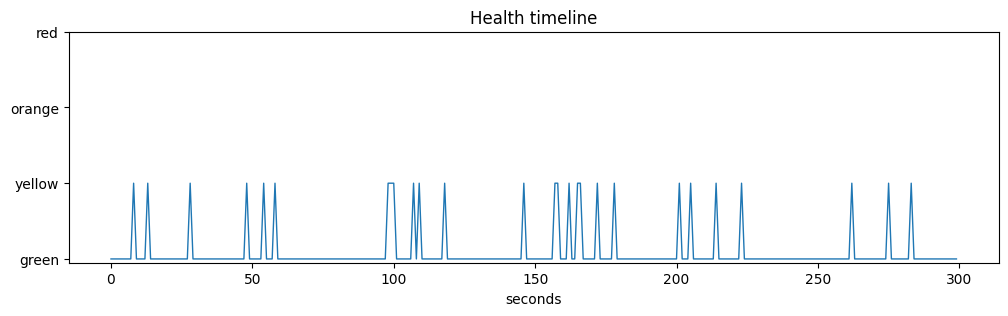

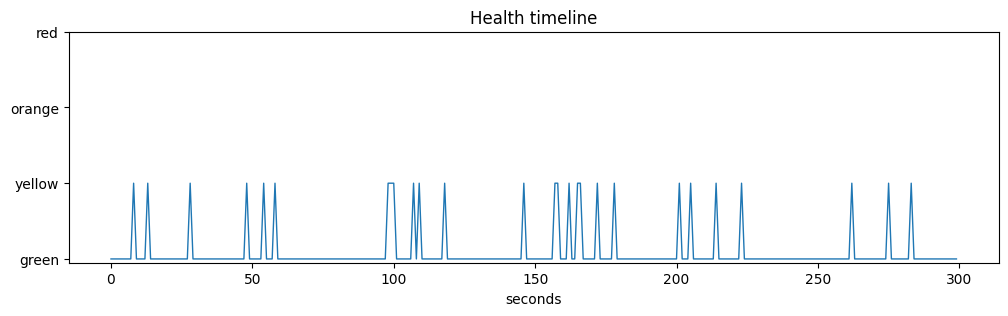

In [49]:
# 模糊逻辑健康状态（绿/黄/橙/红）
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# 模糊逻辑健康状态（绿/黄/橙/红）
def fuzzy_health_state(alarms_3):
    alarms_3 = np.asarray(alarms_3)
    out = []
    for t in range(len(alarms_3)):
        k = int(np.sum(alarms_3[t]))  # 这一秒有几个参数报警(0~3)
        out.append(["green","yellow","orange","red"][k])
    return np.array(out)

def plot_health_timeline(states, title="Health timeline"):
    mapping = {"green":0,"yellow":1,"orange":2,"red":3}
    states = np.asarray(states)

    if states.size == 0:
        raise ValueError("states 为空，说明 alarms_3 为空或生成失败")

    y = np.vectorize(mapping.get)(states)

    fig, ax = plt.subplots(figsize=(12,3))
    ax.plot(y, lw=1)
    ax.set_yticks([0,1,2,3])
    ax.set_yticklabels(["green","yellow","orange","red"])
    ax.set_title(title)
    ax.set_xlabel("seconds")
    plt.show()
    return fig, ax


# 立刻调用，然后出图
# 算 alarms_3，随机示范，出图
if "alarms_3" not in globals():
    alarms_3 = (np.random.rand(300,3) > 0.97)  # 300秒示范

print("alarms_3 shape:", np.asarray(alarms_3).shape, "dtype:", np.asarray(alarms_3).dtype)

states = fuzzy_health_state(alarms_3)
print("states length:", len(states), "unique:", np.unique(states))

fig, ax = plot_health_timeline(states, title="Health timeline")
fig  # 强制 Jupyter 渲染一次


alarms_3 shape: (3960, 3) dtype: bool
states length: 3960 unique states: ['green' 'yellow']


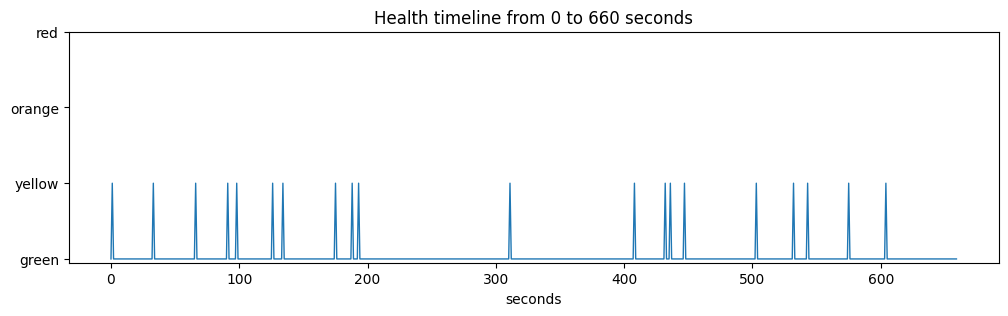

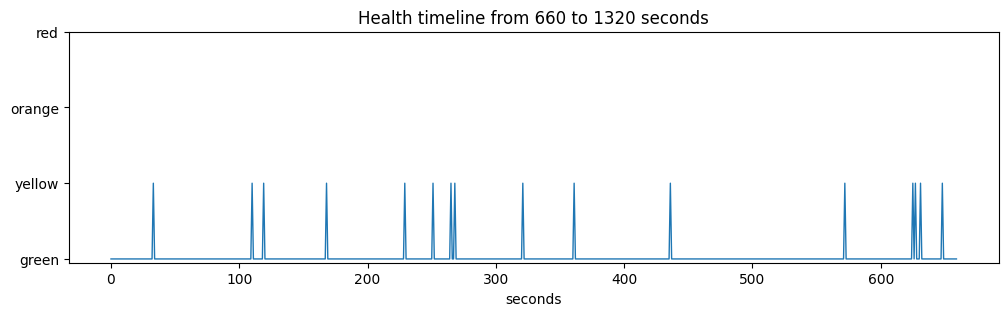

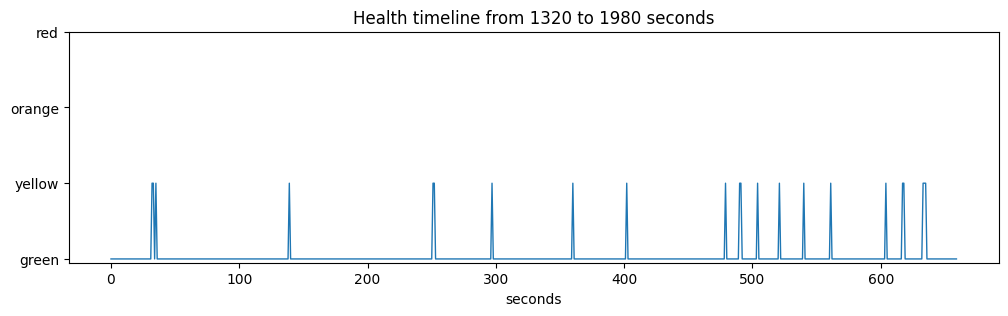

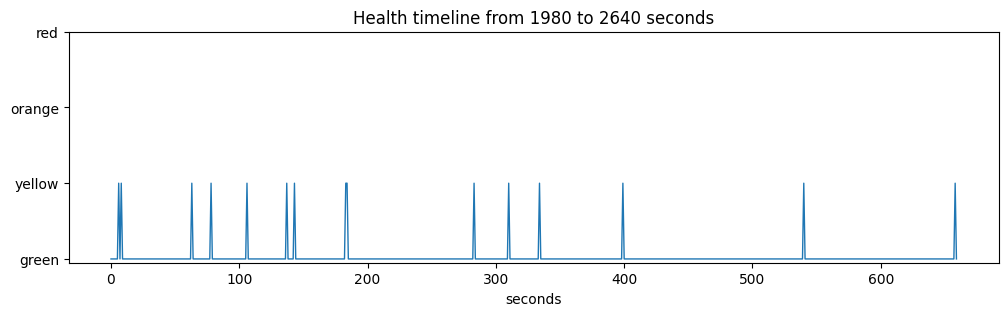

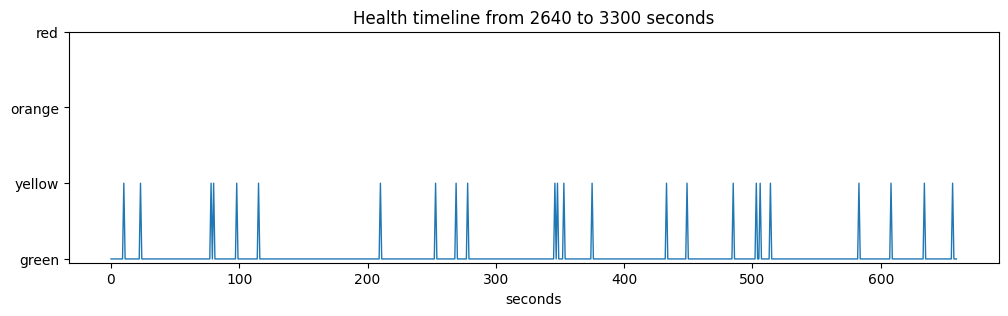

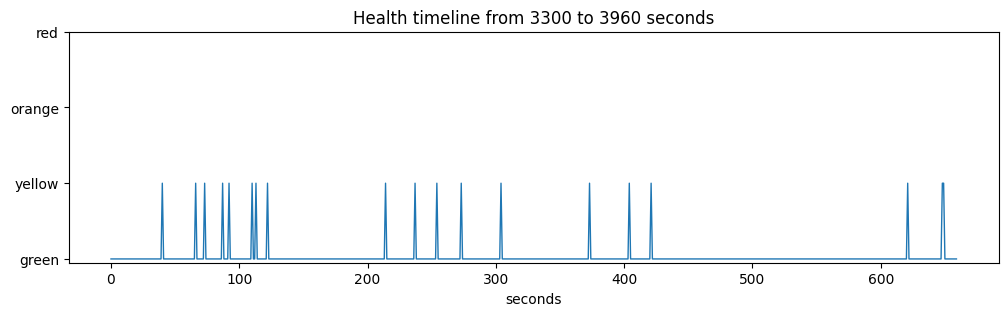

In [50]:
# 模糊逻辑健康状态（绿/黄/橙/红）
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# 模糊逻辑健康状态（绿/黄/橙/红）
def fuzzy_health_state(alarms_3):
    alarms_3 = np.asarray(alarms_3)
    out = []
    for t in range(len(alarms_3)):
        k = int(np.sum(alarms_3[t]))  # 这一秒有几个参数报警(0~3)
        out.append(["green", "yellow", "orange", "red"][k])
    return np.array(out)

def plot_health_timeline(states, title="Health timeline"):
    mapping = {"green": 0, "yellow": 1, "orange": 2, "red": 3}
    states = np.asarray(states)

    if states.size == 0:
        raise ValueError("states 为空，说明 alarms_3 为空或生成失败")

    y = np.vectorize(mapping.get)(states)

    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(y, lw=1)
    ax.set_yticks([0, 1, 2, 3])
    ax.set_yticklabels(["green", "yellow", "orange", "red"])
    ax.set_title(title)
    ax.set_xlabel("seconds")
    plt.show()
    return fig, ax


# 生成完整的 alarms_3 数据，数据时长为 3960 秒（1小时6分钟）
N = 3960  # 3960秒健康状态数据（1小时6分钟）
alarms_3 = (np.random.rand(N, 3) > 0.99)  # 模拟报警：大约 1% 的概率报警（alpha = 0.01）

print("alarms_3 shape:", np.asarray(alarms_3).shape, "dtype:", np.asarray(alarms_3).dtype)

# alarms_3 有 3960 秒数据，先计算健康状态
states = fuzzy_health_state(alarms_3)
print("states length:", len(states), "unique states:", np.unique(states))

# 分段展示健康状态（每660秒分一个图)对应约11分钟每图
step = 660  # 每660秒为一个图（11分钟）
for i in range(0, N, step):
    end_idx = min(i + step, N)
    states_segment = states[i:end_idx]
    plot_health_timeline(states_segment, title=f"Health timeline from {i} to {end_idx} seconds")


In [51]:
# 生成器和判别器（CNN3层）
import torch.nn as nn

class GeneratorCNN1D(nn.Module):
    def __init__(self, z_dim=64, out_len=100):
        super().__init__()
        self.fc = nn.Linear(z_dim, 128 * 25)  # 映射到 (128, 25)
        self.deconv = nn.Sequential(
            nn.ConvTranspose1d(128, 64, kernel_size=4, stride=2, padding=1),  # 25->50
            nn.ReLU(),
            nn.ConvTranspose1d(64, 32, kernel_size=4, stride=2, padding=1),   # 50->100
            nn.ReLU(),
            nn.Conv1d(32, 1, kernel_size=3, padding=1)                        # 输出 (100,)
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 128, 25)
        x = self.deconv(x)
        return x.squeeze(1)

class DiscriminatorCNN1D(nn.Module):
    def __init__(self, in_len=100):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, stride=2, padding=2),  # 100->50
            nn.LeakyReLU(0.2),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2), # 50->25
            nn.LeakyReLU(0.2),
            nn.Conv1d(64, 128, kernel_size=5, stride=2, padding=2),# 25->13
            nn.LeakyReLU(0.2),
        )
        self.fc = nn.Linear(128 * 13, 1)

    def forward(self, x):
        x = x.unsqueeze(1)  # (B, 1, 100)
        h = self.conv(x)
        h = h.reshape(h.size(0), -1)  # flatten
        return self.fc(h).view(-1)


In [52]:
# 物理损失（二次积分）
def double_integral_torch(acc, dt=0.01):
    v = torch.cumsum(acc, dim=1) * dt
    x = torch.cumsum(v, dim=1) * dt
    x = x - x.mean(dim=1, keepdim=True)  # 去漂移
    return x


In [53]:
# GAN训练损失（WGAN-GP+PINN)
from torch.utils.data import DataLoader

def gradient_penalty(D, real, fake, device=device):
    B = real.size(0)
    eps = torch.rand(B, 1, device=device).expand_as(real)
    interp = (eps * real + (1 - eps) * fake).requires_grad_(True)
    d_interp = D(interp)
    grads = torch.autograd.grad(
        d_interp, interp, torch.ones_like(d_interp),
        create_graph=True, retain_graph=True, only_inputs=True
    )[0]
    return ((grads.norm(2, dim=1) - 1) ** 2).mean()

def train_gan_pinn(acc_samples, disp_samples, epochs=200, batch_size=256, z_dim=64, lr=1e-4, n_critic=5, lambda_gp=10.0, lambda_phys=20.0, device=device):
    dl = DataLoader(AccDispDataset(acc_samples, disp_samples), batch_size=batch_size, shuffle=True, drop_last=True, pin_memory=True)
    
    G = GeneratorCNN1D(z_dim=z_dim).to(device)
    D = DiscriminatorCNN1D().to(device)
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.9))
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.9))

    for ep in range(1, epochs + 1):
        for acc_cpu, disp_cpu in dl:
            acc_real = to_device(acc_cpu)  # CUDA
            disp_real = to_device(disp_cpu)  # CUDA

            # Train D
            for _ in range(n_critic):
                z = torch.randn(batch_size, z_dim, device=device)
                acc_fake = G(z).detach()
                lossD = D(acc_fake).mean() - D(acc_real).mean()
                gp = gradient_penalty(D, acc_real, acc_fake)
                lossD_total = lossD + lambda_gp * gp
                optD.zero_grad()
                lossD_total.backward()
                optD.step()

            # Train G (GAN + PINN)
            z = torch.randn(batch_size, z_dim, device=device)
            acc_fake = G(z)
            disp_fake = double_integral_torch(acc_fake, dt=0.01)

            lossG_gan = -D(acc_fake).mean()
            lossG_phys = ((disp_fake - disp_real) ** 2).mean()
            lossG = lossG_gan + lambda_phys * lossG_phys

            optG.zero_grad()
            lossG.backward()
            optG.step()

        if ep % 10 == 0 or ep == 1:
            print(f"Epoch {ep:03d} | lossD {lossD.item():.4f} | lossG_gan {lossG_gan.item():.4f} | lossG_phys {lossG_phys.item():.6f}")

    return G, D


In [55]:
# 生成加速度和位移
def generate_acc_and_disp(G, n=16, z_dim=64, device=device):
    G.eval()
    z = torch.randn(n, z_dim, device=device)
    with torch.no_grad():
        acc = G(z)
        disp = double_integral_torch(acc, dt=0.01)
    return acc.detach().cpu().numpy(), disp.detach().cpu().numpy()



Training AE for activity
Epoch 001 | train MAE 0.139090 | test MAE 0.012207
Epoch 010 | train MAE 0.009288 | test MAE 0.009124
Epoch 020 | train MAE 0.007308 | test MAE 0.007259
Epoch 030 | train MAE 0.007046 | test MAE 0.007196
Epoch 040 | train MAE 0.006941 | test MAE 0.007016
Epoch 050 | train MAE 0.006820 | test MAE 0.006708

Training AE for mobility
Epoch 001 | train MAE 0.091036 | test MAE 0.041288
Epoch 010 | train MAE 0.017179 | test MAE 0.017522
Epoch 020 | train MAE 0.016114 | test MAE 0.015978
Epoch 030 | train MAE 0.013376 | test MAE 0.013513
Epoch 040 | train MAE 0.012797 | test MAE 0.013402
Epoch 050 | train MAE 0.012520 | test MAE 0.012864

Training AE for complexity
Epoch 001 | train MAE 0.067381 | test MAE 0.027343
Epoch 010 | train MAE 0.023839 | test MAE 0.024914
Epoch 020 | train MAE 0.006145 | test MAE 0.006120
Epoch 030 | train MAE 0.006215 | test MAE 0.006145
Epoch 040 | train MAE 0.006029 | test MAE 0.006593
Epoch 050 | train MAE 0.006064 | test MAE 0.005861


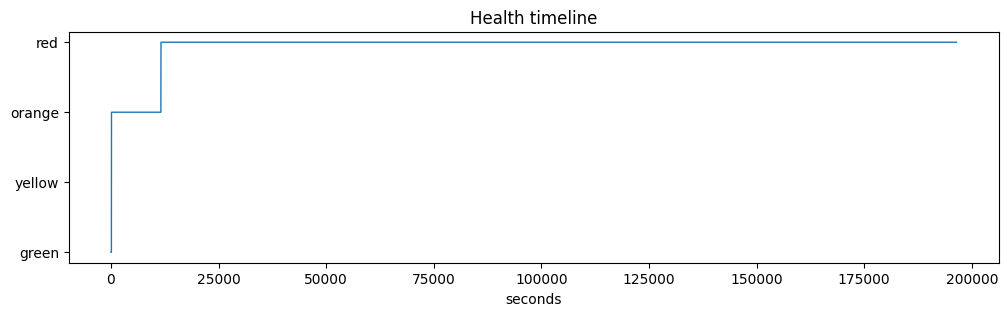

(<Figure size 1200x300 with 1 Axes>,
 <Axes: title={'center': 'Health timeline'}, xlabel='seconds'>)

In [60]:
# 完整流程示例
# ====== 1) 加载正常数据 ======
normal_folder = "C:\\Users\\22140\\OneDrive\\Desktop\\CUSUM\\DataAINOA"
st_norm = load_mseed_folder(normal_folder, channel_list, 100.0)
seg_norm, _ = segment_stream_1s(st_norm, fs=100)
hjorth_normal, _ = compute_hjorth_features(seg_norm)

# ====== 2) 划分和标准化 ======
Xtr_list, Xte_list, scalers = split_and_scale_per_param(hjorth_normal)

# ====== 3) 训练 AE ======
ae_models = train_three_aes(Xtr_list, Xte_list, device=device)

# ====== 4) 加载全量数据 ======
all_folder = "C:\\Users\\22140\\OneDrive\\Desktop\\CUSUM\\DataAINOA"
st_all = load_mseed_folder(all_folder, channel_list, 100.0)
seg_all, _ = segment_stream_1s(st_all, fs=100)
hjorth_all, _ = compute_hjorth_features(seg_all)

# ====== 5) 计算重构误差 ======
errors_all = reconstruction_errors(ae_models, scalers, hjorth_all, device=device)
errors_norm = reconstruction_errors(ae_models, scalers, hjorth_normal, device=device)

# ====== 6) 运行 CUSUM + 模糊健康状态 ======
W_all, alarms = run_cusum_all(errors_all, errors_norm, alpha=0.01)
states = fuzzy_health_state(alarms)
plot_health_timeline(states)
